In [61]:
from traceback import print_tb

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import holidays

from haversine import haversine

df = pd.read_csv('../data/porto.csv')

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 7)


# Exploratory Data Analysis (EDA)

## 1. Setup

### 1.1 Imports

In [104]:

import ast
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import holidays

from haversine import haversine
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 7)

In [110]:
def compute_distance(polyline) -> float:
    """Return the total route distance in kilometres."""
    if len(polyline) < 2:
        return 0

    distance = 0
    for start, end in zip(polyline, polyline[1:]):
        # POLYLINE uses longitude, latitude; haversine expects latitude, longitude.
        distance += haversine((start[1], start[0]), (end[1], end[0]), unit="km")

    return distance

### 1.2 Helper Functions

### 1.3 Load Dataset

In [107]:
DATA_PATH = "../data/porto.csv"
df = pd.read_csv(DATA_PATH)

## 2. Dataset Overview

In [108]:
print("Shape:", df.shape)

Shape: (1710670, 9)


In [109]:
column_info = pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str),
    "Non-null values": df.notna().sum(),
    "Missing values": df.isna().sum(),
    "Unique values": df.nunique()
})

display(column_info)

,Column,Data type,Non-null values,Missing values,Unique values
TRIP_ID,TRIP_ID,int64,1710670,0,1710589
CALL_TYPE,CALL_TYPE,str,1710670,0,3
ORIGIN_CALL,ORIGIN_CALL,float64,364770,1345900,57105
ORIGIN_STAND,ORIGIN_STAND,float64,806579,904091,63
TAXI_ID,TAXI_ID,int64,1710670,0,448
TIMESTAMP,TIMESTAMP,int64,1710670,0,1655366
DAY_TYPE,DAY_TYPE,str,1710670,0,1
MISSING_DATA,MISSING_DATA,bool,1710670,0,2
POLYLINE,POLYLINE,str,1710670,0,1703650


In [17]:
display(df.head())

,TRIP_ID,CALL_TYPE,ORIGIN_CALL,ORIGIN_STAND,TAXI_ID,TIMESTAMP,DAY_TYPE,MISSING_DATA,POLYLINE
0,1372636858620000589,C,NaN,NaN,20000589,1372636858,A,False,"[[-8.618643,41.141412],[-8.618499,41.141376],[..."
1,1372637303620000596,B,NaN,7.0,20000596,1372637303,A,False,"[[-8.639847,41.159826],[-8.640351,41.159871],[..."
2,1372636951620000320,C,NaN,NaN,20000320,1372636951,A,False,"[[-8.612964,41.140359],[-8.613378,41.14035],[-..."
3,1372636854620000520,C,NaN,NaN,20000520,1372636854,A,False,"[[-8.574678,41.151951],[-8.574705,41.151942],[..."
4,1372637091620000337,C,NaN,NaN,20000337,1372637091,A,False,"[[-8.645994,41.18049],[-8.645949,41.180517],[-..."


In [18]:
display(df.describe(include="all"))

,TRIP_ID,CALL_TYPE,ORIGIN_CALL,ORIGIN_STAND,TAXI_ID,TIMESTAMP,DAY_TYPE,MISSING_DATA,POLYLINE
count,1.710670e+06,1710670,364770.000000,806579.000000,1.710670e+06,1.710670e+06,1710670,1710670,1710670
unique,NaN,3,NaN,NaN,NaN,NaN,1,2,1703650
top,NaN,B,NaN,NaN,NaN,NaN,A,False,[]
freq,NaN,817881,NaN,NaN,NaN,NaN,1710670,1710660,5901
mean,1.388622e+18,NaN,24490.363018,30.272381,2.000035e+07,1.388622e+09,NaN,NaN,NaN
std,9.180944e+15,NaN,19624.290043,17.747840,2.112405e+02,9.180944e+06,NaN,NaN,NaN
min,1.372637e+18,NaN,2001.000000,1.000000,2.000000e+07,1.372637e+09,NaN,NaN,NaN
25%,1.380731e+18,NaN,6593.000000,15.000000,2.000017e+07,1.380731e+09,NaN,NaN,NaN
50%,1.388493e+18,NaN,18755.000000,27.000000,2.000034e+07,1.388493e+09,NaN,NaN,NaN
75%,1.396750e+18,NaN,40808.000000,49.000000,2.000052e+07,1.396750e+09,NaN,NaN,NaN


## 2. Data Preparation

In [44]:
df["DATETIME"] = pd.to_datetime(df["TIMESTAMP"], unit="s")
df["DATE"] = df["DATETIME"].dt.date
df["POLYLINE"] = df["POLYLINE"].apply(ast.literal_eval)
df["GPS_POINTS"] = df["POLYLINE"].apply(len)
df["DURATION"] = (df["GPS_POINTS"] - 1) * 15
df["DISTANCE"] = df["POLYLINE"].apply(compute_distance)

## 4. Distribution of Call Types

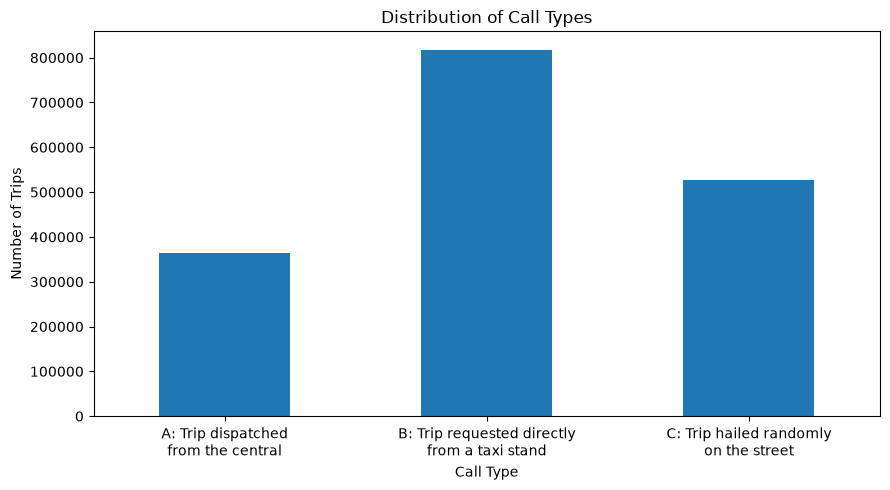

In [70]:
call_type_names = {
    "A": "A: Trip dispatched\nfrom the central",
    "B": "B: Trip requested directly\nfrom a taxi stand",
    "C": "C: Trip hailed randomly\non the street"
}

call_type_counts = (
    df["CALL_TYPE"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
)

call_type_counts.index = call_type_counts.index.map(call_type_names)

ax = call_type_counts.plot(
    kind="bar",
    figsize=(9, 5),
    title="Distribution of Call Types",
    xlabel="Call Type",
    ylabel="Number of Trips",
    rot=0
)

ax.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

## 3. Distribution of Day Types

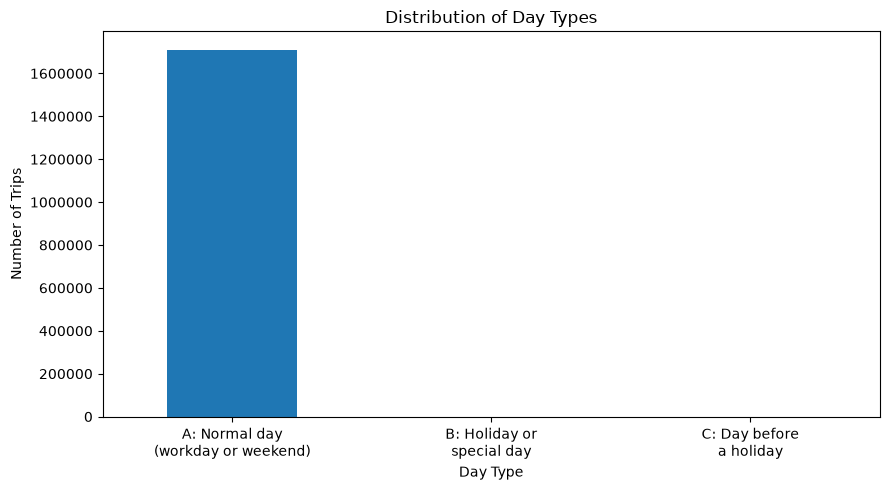

In [71]:
daytype_names = {
    "A": "A: Normal day\n(workday or weekend)",
    "B": "B: Holiday or\nspecial day",
    "C": "C: Day before\na holiday"
}

daytype_counts = (
    df["DAY_TYPE"]
    .value_counts()
    .reindex(["A", "B", "C"], fill_value=0)
)

daytype_counts.index = daytype_counts.index.map(daytype_names)

ax = daytype_counts.plot(
    kind="bar",
    figsize=(9, 5),
    title="Distribution of Day Types",
    xlabel="Day Type",
    ylabel="Number of Trips",
    rot=0
)

ax.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

## 4. Number of Trips per Hour, Weekday and Month

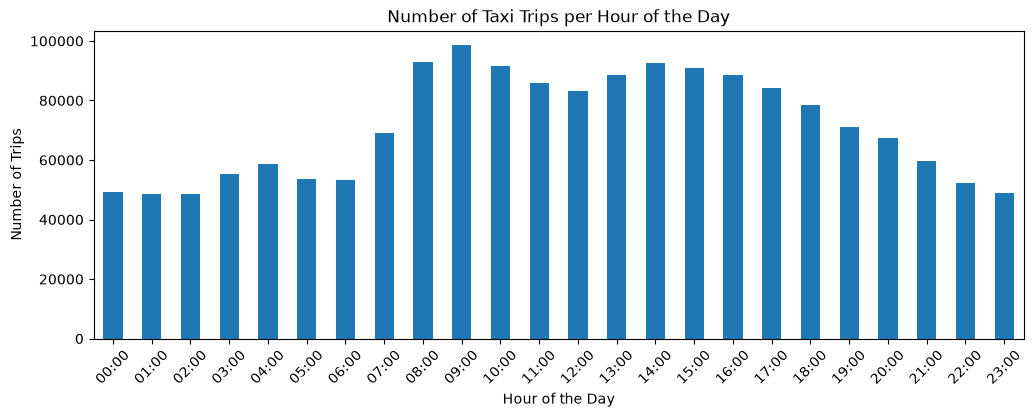

In [57]:
trips_per_hour = (
    df.groupby(df["DATETIME"].dt.hour)
      .size()
      .reindex(range(24), fill_value=0)
)

ax = trips_per_hour.plot(
    kind="bar",
    figsize=(12, 4),
    title="Number of Taxi Trips per Hour of the Day",
    xlabel="Hour of the Day",
    ylabel="Number of Trips"
)

ax.set_xticklabels(
    [f"{hour:02d}:00" for hour in range(24)],
    rotation=45
);

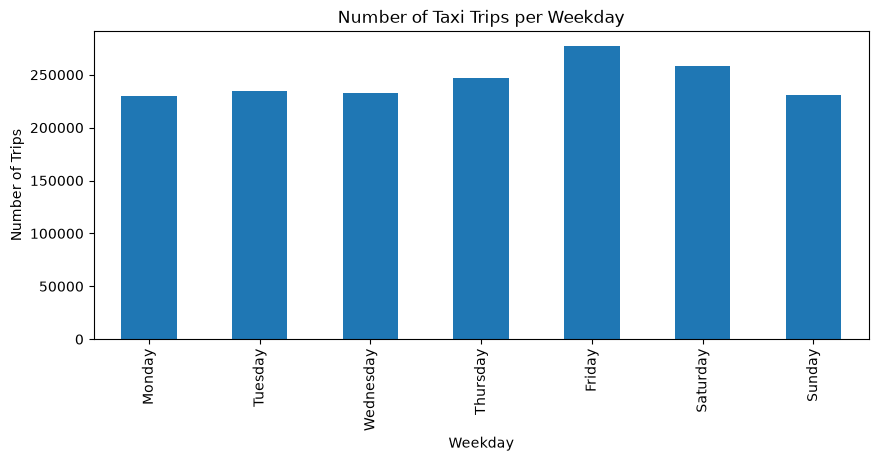

In [47]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

trips_per_weekday = (
    df.groupby(df["DATETIME"].dt.day_name())
      .size()
      .reindex(weekday_order)
)

trips_per_weekday.plot(
    kind="bar",
    figsize=(10, 4),
    title="Number of Taxi Trips per Weekday",
    xlabel="Weekday",
    ylabel="Number of Trips"
);

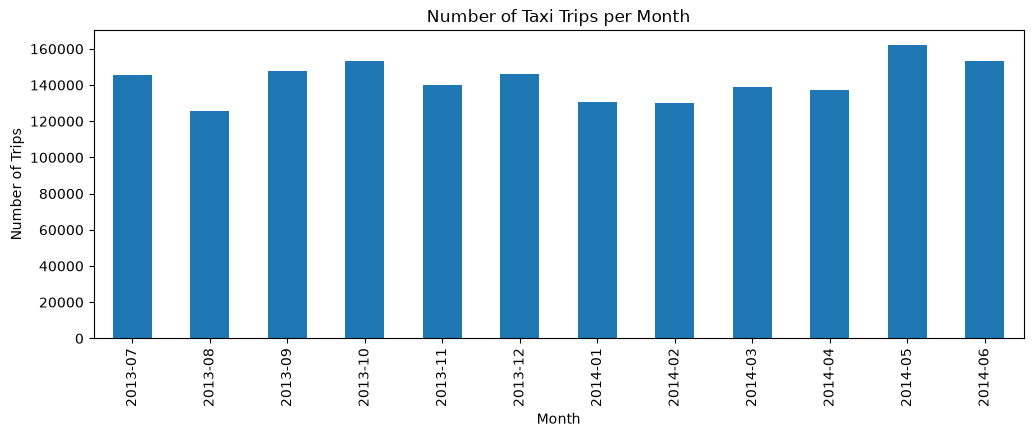

In [48]:
trips_per_month = (
    df.groupby(df["DATETIME"].dt.to_period("M"))
      .size()
      .sort_index()
)

trips_per_month.plot(
    kind="bar",
    figsize=(12, 4),
    title="Number of Taxi Trips per Month",
    xlabel="Month",
    ylabel="Number of Trips"
);

## 5. Distribution of GPS Points per Trip

Text(0, 0.5, 'Number of Trips (log scale)')

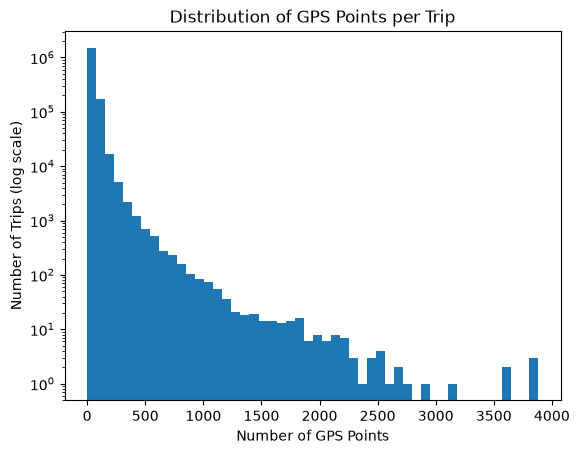

In [63]:
ax = df["GPS_POINTS"].plot(
    kind="hist",
    bins=50,
    title="Distribution of GPS Points per Trip",
    xlabel="Number of GPS Points"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")

## 6. Distribution of Trip Duration per Trip

Text(0, 0.5, 'Number of Trips (log scale)')

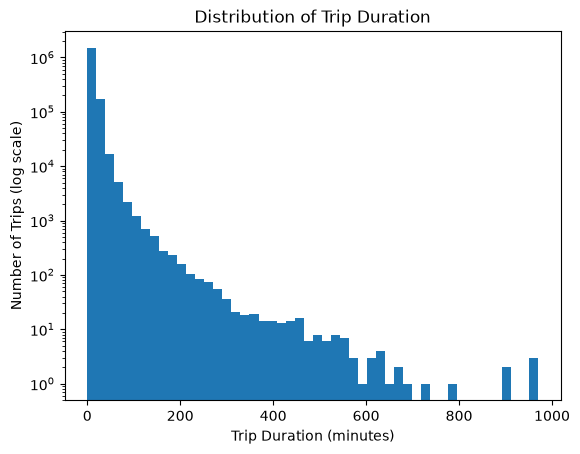

In [65]:
ax = (df["DURATION"] / 60).plot(
    kind="hist",
    bins=50,
    title="Distribution of Trip Duration",
    xlabel="Trip Duration (minutes)"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")

## 7. Top 10 Most Active Taxi Drivers

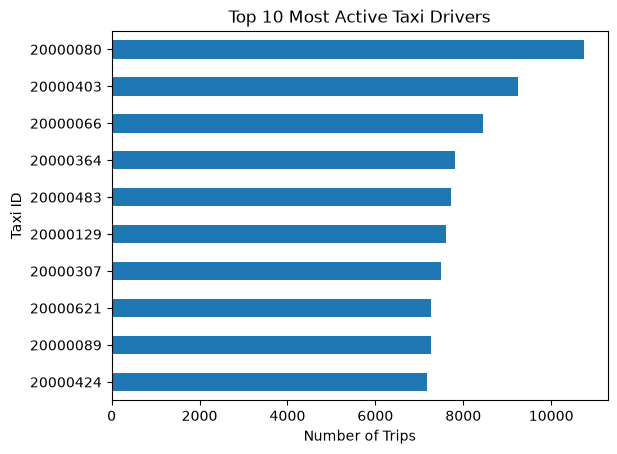

In [53]:
top_taxis = df["TAXI_ID"].value_counts().head(10)

top_taxis.sort_values().plot(
    kind="barh",
    title="Top 10 Most Active Taxi Drivers",
    xlabel="Number of Trips",
    ylabel="Taxi ID"
);

## 8. Number of Trips per Taxi

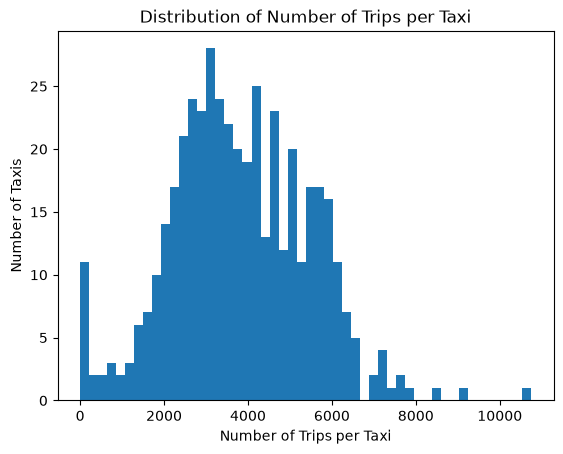

In [66]:
trips_per_taxi = df.groupby("TAXI_ID").size()

trips_per_taxi.plot(
    kind="hist",
    bins=50,
    title="Distribution of Number of Trips per Taxi",
    xlabel="Number of Trips per Taxi",
    ylabel="Number of Taxis"
);

## 9. Distribution of Trip Distance

Text(0, 0.5, 'Number of Trips (log scale)')

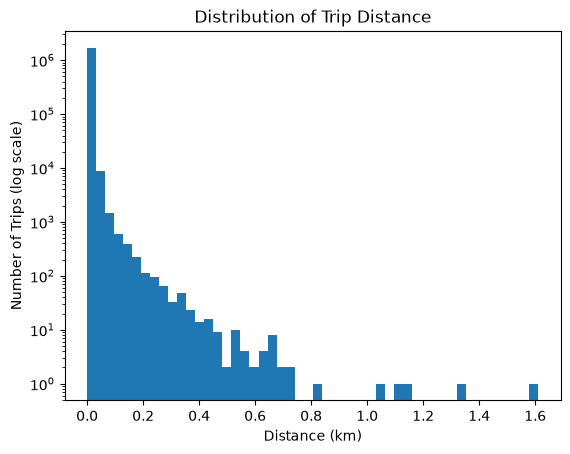

In [68]:
ax = df["DISTANCE"].plot(
    kind="hist",
    bins=50,
    title="Distribution of Trip Distance",
    xlabel="Distance (km)"
)

ax.set_yscale("log")
ax.set_ylabel("Number of Trips (log scale)")

In [3]:
df.head()
df.info()
df.describe(include='all')

<class 'pandas.DataFrame'>
RangeIndex: 1710670 entries, 0 to 1710669
Data columns (total 9 columns):
 #   Column        Dtype  
---  ------        -----  
 0   TRIP_ID       int64  
 1   CALL_TYPE     str    
 2   ORIGIN_CALL   float64
 3   ORIGIN_STAND  float64
 4   TAXI_ID       int64  
 5   TIMESTAMP     int64  
 6   DAY_TYPE      str    
 7   MISSING_DATA  bool   
 8   POLYLINE      str    
dtypes: bool(1), float64(2), int64(3), str(3)
memory usage: 106.0 MB


,TRIP_ID,CALL_TYPE,ORIGIN_CALL,ORIGIN_STAND,TAXI_ID,TIMESTAMP,DAY_TYPE,MISSING_DATA,POLYLINE
count,1.710670e+06,1710670,364770.000000,806579.000000,1.710670e+06,1.710670e+06,1710670,1710670,1710670
unique,NaN,3,NaN,NaN,NaN,NaN,1,2,1703650
top,NaN,B,NaN,NaN,NaN,NaN,A,False,[]
freq,NaN,817881,NaN,NaN,NaN,NaN,1710670,1710660,5901
mean,1.388622e+18,NaN,24490.363018,30.272381,2.000035e+07,1.388622e+09,NaN,NaN,NaN
std,9.180944e+15,NaN,19624.290043,17.747840,2.112405e+02,9.180944e+06,NaN,NaN,NaN
min,1.372637e+18,NaN,2001.000000,1.000000,2.000000e+07,1.372637e+09,NaN,NaN,NaN
25%,1.380731e+18,NaN,6593.000000,15.000000,2.000017e+07,1.380731e+09,NaN,NaN,NaN
50%,1.388493e+18,NaN,18755.000000,27.000000,2.000034e+07,1.388493e+09,NaN,NaN,NaN
75%,1.396750e+18,NaN,40808.000000,49.000000,2.000052e+07,1.396750e+09,NaN,NaN,NaN


In [59]:
df["DATETIME"] = pd.to_datetime(df["TIMESTAMP"], unit="s")

Data Quality

<Axes: >

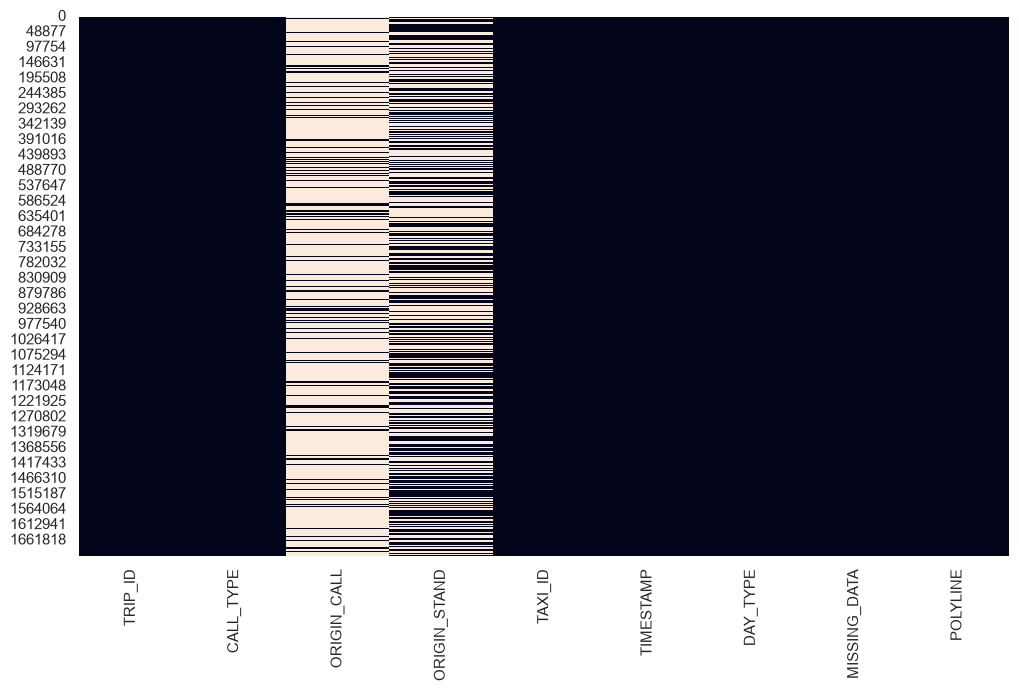

In [43]:
# Count actual null values (NaN/None) in every column.
# The string '[]' and the boolean True are not null values.
sns.heatmap(df.isnull(), cbar=False)

#We can see that there are a lot of null values for ORIGIN_CALL and ORIGIN_STAND

#This is because those values are only relevenat for some CALL types. Will now check that those rules are upheld


In [62]:
holiday = df[df["DAY_TYPE"]!= "A"]
print(holiday)
#All days are counted as Normal Days, it's unreasonable to believe that no taxi trips were done on holidays and the day before?


porto_holidays = holidays.country_holidays(
    "PT",
    subdiv="13",  # Porto
    years=[2013, 2014],
    language="en_US"
)

for date, name in sorted(porto_holidays.items()):
    print(date, name)

    from datetime import timedelta

trip_dates = pd.to_datetime(
    df["TIMESTAMP"], unit="s", utc=True
).dt.tz_convert("Europe/Lisbon").dt.date

holiday_dates = set(porto_holidays.keys())
days_before = {date - timedelta(days=1) for date in holiday_dates}

on_holiday = trip_dates.isin(holiday_dates)
before_holiday = trip_dates.isin(days_before)

print("Trips starting on holidays:", on_holiday.sum())
print("Trips starting the day before holidays:", before_holiday.sum())

Empty DataFrame
Columns: [TRIP_ID, CALL_TYPE, ORIGIN_CALL, ORIGIN_STAND, TAXI_ID, TIMESTAMP, DAY_TYPE, MISSING_DATA, POLYLINE]
Index: []
2013-01-01 New Year's Day
2013-03-29 Good Friday
2013-03-31 Easter Sunday
2013-04-25 Freedom Day
2013-05-01 Labor Day
2013-06-10 Day of Portugal, Camões, and the Portuguese Communities
2013-06-24 Saint John's Day
2013-08-15 Assumption Day
2013-12-08 Immaculate Conception
2013-12-25 Christmas Day
2014-01-01 New Year's Day
2014-04-18 Good Friday
2014-04-20 Easter Sunday
2014-04-25 Freedom Day
2014-05-01 Labor Day
2014-06-10 Day of Portugal, Camões, and the Portuguese Communities
2014-06-24 Saint John's Day
2014-08-15 Assumption Day
2014-12-08 Immaculate Conception
2014-12-25 Christmas Day
Trips starting on holidays: 47274
Trips starting the day before holidays: 49392


In [52]:
#First we check for Call Type, check that only call type A have origina stand values

df_call_A = df[df["CALL_TYPE"] == "A"]
df_call_not_A = df[df["CALL_TYPE"] != "A"]

# Find how many null values there are in ORIGIN_STAND for call type A (lower is better)
print(df_call_A["ORIGIN_CALL"].isnull().sum(), "out of ",len(df_call_A), "central dispatched taxis have no value for caller")

# Find out how many non-central dispatched taxis have value for caller (lower is better)
print(df_call_not_A["ORIGIN_CALL"].notna().sum(), "out of ",len(df_call_not_A), "non-central dispatched taxis have value for caller")

df_call_B = df[df["CALL_TYPE"] == "B"]
df_call_not_B = df[df["CALL_TYPE"] != "B"]

print(df_call_B["ORIGIN_STAND"].isnull().sum(), "out of ",len(df_call_B), "Waiting taxi stands, have not a taxi stand ID")

print(df_call_not_B["ORIGIN_STAND"].notna().sum(), "out of ",len(df_call_not_B), "Non waiting taxi stands, have a taxi stand ID")


0 out of  364770 central dispatched taxis have no value for caller
0 out of  1345900 non-central dispatched taxis have value for caller
11302 out of  817881 Waiting taxi stands, have not a taxi stand ID
0 out of  892789 Non waiting taxi stands, have a taxi stand ID


10 rows are marked as missing data
5901 rows have empty POLYLINE, ala no location data
5911 rows are missing location data
The missing rows makes up 0.35% of the dataset
0 rows have both MISSING_DATA == True and empty POLYLINE


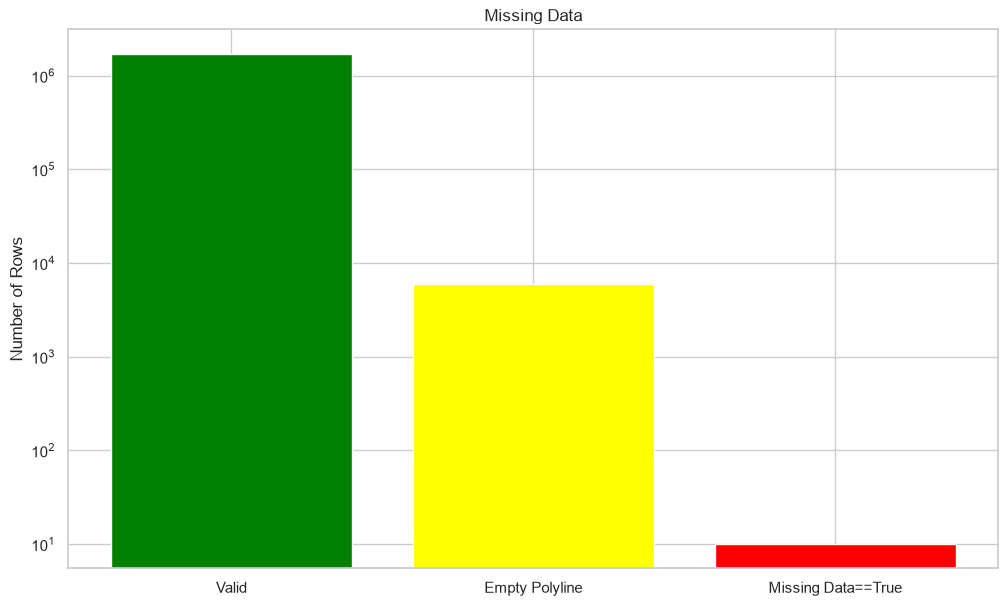

                     TRIP_ID CALL_TYPE  ORIGIN_CALL  ORIGIN_STAND   TAXI_ID  \
105621   1374554455620000625         B          NaN          23.0  20000625   
171397   1375863510620000454         B          NaN          62.0  20000454   
299137   1378544246620000057         B          NaN          55.0  20000057   
457486   1381233613620000387         C          NaN           NaN  20000387   
738466   1386346894620000904         C          NaN           NaN  20000904   
782321   1387137779620000640         C          NaN           NaN  20000640   
848552   1388351478620000678         A       9738.0           NaN  20000678   
932391   1390005983620000640         C          NaN           NaN  20000640   
1275934  1396631707620000163         C          NaN           NaN  20000163   
1432196  1399405185620000508         C          NaN           NaN  20000508   

          TIMESTAMP DAY_TYPE  MISSING_DATA  \
105621   1374554455        A          True   
171397   1375863510        A          

In [33]:
# First, we create a panda series for only the rows where MISSING_DATA == true
missing_data_marked = df[df["MISSING_DATA"] == True]

#Then one for where empty POLYLINE
empty_polyline = df[df["POLYLINE"] == "[]"]

both = df[(df["MISSING_DATA"] == True) & (df["POLYLINE"] == "[]")]

missing_data_all = len(missing_data_marked) + len(empty_polyline) - len(both)

print(len(missing_data_marked), "rows are marked as missing data")
print(len(empty_polyline), "rows have empty POLYLINE, ala no location data")
print(missing_data_all, "rows are missing location data")
print(f"The missing rows makes up {missing_data_all/len(df)*100:.2f}% of the dataset")

print(len(both), "rows have both MISSING_DATA == True and empty POLYLINE")

# We visualize this

labels = ["Valid", "Empty Polyline", "Missing Data==True"]
numbers = [len(df) - missing_data_all, len(empty_polyline), len(missing_data_marked)]
colours = ["green", "yellow", "red"]

plt.bar(x=labels, height=numbers, color=colours)
plt.title("Missing Location Data")
plt.ylabel("Number of Rows")
plt.yscale("log") # Necessary to visualize the difference
plt.show()

print(missing_data_marked)


In [111]:
# Outlier analysis of trip distance
sample_df = df.sample(n=min(10_000, len(df)), random_state=42).copy()
sample_df["POLYLINE"] = sample_df["POLYLINE"].apply(
    lambda route: ast.literal_eval(route) if isinstance(route, str) else route
)

# Incomplete routes and routes with fewer than two points cannot give a full trip distance.
valid_routes = (~sample_df["MISSING_DATA"]) & (sample_df["POLYLINE"].str.len() >= 2)
print(f"Excluded {int((~valid_routes).sum())} sampled trips with incomplete or too few GPS points.")
sample_df = sample_df.loc[valid_routes].copy()
if sample_df.empty:
    raise ValueError("No usable routes in the sample.")

sample_df["TRIP_DISTANCE_KM"] = sample_df["POLYLINE"].apply(compute_distance)
distances = sample_df["TRIP_DISTANCE_KM"]

q1, q3 = distances.quantile([0.25, 0.75])
iqr = q3 - q1
lower_limit = q1 - 1.5 * iqr
upper_limit = q3 + 1.5 * iqr

outliers = sample_df[
    (distances < lower_limit) | (distances > upper_limit)
]

print(f"Q1: {q1:.2f} km, Q3: {q3:.2f} km")
print(f"IQR: {iqr:.2f} km")
print(f"Lower limit: {lower_limit:.2f} km, upper limit: {upper_limit:.2f} km")
print(f"Outliers: {len(outliers)} of {len(sample_df)} trips ({len(outliers) / len(sample_df):.2%})")

Excluded 193 sampled trips with incomplete or too few GPS points.
Q1: 2.44 km, Q3: 6.52 km
IQR: 4.08 km
Lower limit: -3.68 km, upper limit: 12.64 km
Outliers: 726 of 9807 trips (7.40%)


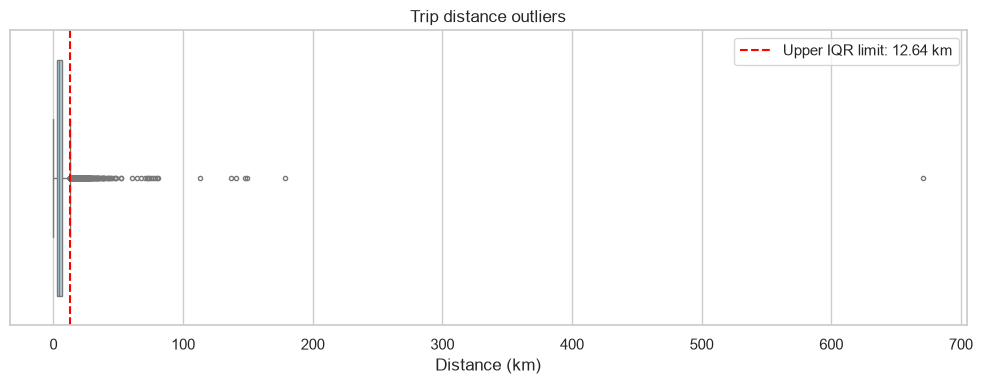

In [112]:
fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(x=distances, color="lightblue", whis=1.5, fliersize=3, ax=ax)
ax.axvline(upper_limit, color="red", linestyle="--",
           label=f"Upper IQR limit: {upper_limit:.2f} km")
if lower_limit >= 0:
    ax.axvline(lower_limit, color="grey", linestyle="--",
               label=f"Lower IQR limit: {lower_limit:.2f} km")
ax.set(title="Trip distance outliers", xlabel="Distance (km)")
ax.legend()
plt.tight_layout()
plt.show()

The IQR rule flags trips outside Q1 - 1.5 × IQR and Q3 + 1.5 × IQR. These limits describe this sample, so a different sample may give slightly different results.

A long trip is not necessarily a recording error. The flagged trips are kept for inspection rather than removed. The boxplot whisker ends at the most extreme observed value within the limit; the dashed line marks the limit itself.